In [45]:
import numpy as np
import pandas as pd
import glob
import os
import shutil
import matplotlib.pyplot as plt
import seaborn as sns
import pendulum as pdl
from scipy.signal import find_peaks


In [31]:
resultfolder = "preliminary/ADDJTV"
NEXP = 300


def get_results_by_id(id, path: str = None):
    path = f"QMC-Initial/{resultfolder}/{id}/openlab-sensors-export.csv" if path is None else path
    try:
        loaded_data = load_num_data(path)
        if loaded_data is None:
            raise FileNotFoundError()
        crossings = loaded_data[loaded_data["LC "] >= 300] 
        crossings = crossings[crossings["LC "] <= 400] 
        return crossings
    except FileNotFoundError:
        print(f"FILE for {id} NOT FOUND")
        
def get_np_data(df: pd.DataFrame):
    unique_sensors = df["NODE "].unique()
    rows = {}
    for s in unique_sensors:
        npar = df[df["NODE "] == s][df.columns[-2]].to_numpy()
        # count records between max and middle
        # print(np.argmax(npar), len(npar)-np.argmax(npar)-1)
        npar = np.concatenate([npar, np.flip(npar,0)])
        # npar = np.pad(npar, 1)
        rows[s]=npar
    return rows

In [32]:
CREEP_TIMELINE = {
    "concreing the slab": {"start_date": pdl.parse("2024-02-01 11:59:59"),
         "end_date": pdl.parse("2024-02-01 11:59:59"),
         "lc-start": 4045,
         "simulation_steps": 1,
         },
#     "creep after concreting": {"start_date": pdl.parse("2024-02-01 12:00:00"),
#          "end_date": pdl.parse("2024-02-22 11:59:58"),
#          "lc-start": 4047,
#          "simulation_steps": 3,
#          }, #TODO: recompute the simulations
    "scaffolding removal": {"start_date": pdl.parse("2024-02-22 11:59:59"),
         "end_date": pdl.parse("2024-02-22 11:59:59"),
         "lc-start": 4064,
         "simulation_steps": 1,
         },
    "creep until additional dead load": {"start_date": pdl.parse("2024-02-22 12:00:00"),
         "end_date": pdl.parse("2024-03-18 11:59:58"),
         "lc-start": 4065,
         "simulation_steps": 5,
         },
    "additional dead load": {"start_date": pdl.parse("2024-03-18 11:59:59"),
         "end_date": pdl.parse("2024-03-18 11:59:59"),
         "lc-start": 4070,
         "simulation_steps": 1,
         },
    "creep until load test": {"start_date": pdl.parse("2024-03-18 12:00:00"),
         "end_date": pdl.parse("2025-05-06 12:00:00"),
         "lc-start": 4075,
         "simulation_steps": 10,
         },
}

CROSSING_TIMELINE = {
     "lighter vehicle crossing": {
          "start_date": pdl.parse("2024-03-18 12:00:00"),
          "end_date": pdl.parse("2025-05-06 12:00:00"),
          "lc-start": 300,
          "simulation_steps": 10,
         },
}

In [33]:
def load_num_data(path):
    if os.path.exists(path):
        loaded_data = pd.read_csv(path)
        loaded_data[loaded_data.columns[3:]] = loaded_data[loaded_data.columns[3:]].apply(lambda x: x.str.replace(',', '.'))
        loaded_data[loaded_data.columns[3:]] = loaded_data[loaded_data.columns[3:]].apply(lambda x: pd.to_numeric(x, errors='coerce'))
        return loaded_data

def from_mrad_to_mm_per_m(mrad):
    """Convert mrad to mm/m"""
    # mrad.str.replace(",", ".", inplace=True)
    values = pd.to_numeric(mrad, errors="raise")
    return np.tan(values * 1e-3) * 1000

def get_qoi(dftemp: pd.DataFrame, sensor):
    dftemp = dftemp.copy()
    QoI_dict = {
        "Tilt-X": from_mrad_to_mm_per_m(dftemp["phi-Y [mrad]"].values),
        "Tilt-Y": from_mrad_to_mm_per_m(dftemp["phi-X [mrad]"].values),
        "Displacement-X": dftemp["u-X [mm]"].values,
        "Displacement-Y": dftemp["u-Y [mm]"].values,
        "Displacement-Z": dftemp["u-Z [mm]"].values,
    }
    try:
        qoi = QoI_dict[sensor["QoI"]]
    except KeyError:
        print(f"QoI {sensor['QoI']} not found for sensor {sensor['Name']}")
        qoi = None
    return qoi
    
def get_corrected_sensor_name(sensor):
    SensorNameDict = {
        "NGS": "TIL",
        "FT": "PE",
        "BU": "CB",
    }
    sensor_name = sensor["Name"]
    for key, value in SensorNameDict.items():
        sensor_name = sensor_name.replace(key, value)
    return sensor_name

In [34]:
path = f"QMC-Initial/{resultfolder}/1/openlab-sensors-export.csv"
# results = pd.read_csv(path)
results = load_num_data(path)

In [35]:
# def find_min_lc_num(dftemp: pd.DataFrame = None) -> int:
#     """
#     Find the minimum loadcase number in the loadcase_timesheet.
    
#     Args:
#         dftemp (pd.DataFrame): The dataframe from which to find the minimum loadcase number.
        
#     Returns:
#         int: The minimum loadcase number in the loadcase_timesheet. If the dataframe is empty, returns 0.
#     """
#     dftemp = dftemp.query("`LC-title ` == 'Creep until start of load test'")
#     if not dftemp.empty:
#         return dftemp["LC "].min()
#     else:
#         raise ValueError("The loadcase_timesheet is empty or does not contain the specified loadcase title.")

def add_relevant_loadcases(loadcase_timesheet, lc_title: str, start_date: pdl.datetime, simulation_duration: pd.Interval, simulation_steps: int, start_lc_num: int = None) -> pd.DataFrame:
    """
    Add relevant loadcases to the loadcase_timesheet
    
    Args:
        loadcase_timesheet (pd.DataFrame): The loadcase timesheet to which the loadcases will be added.
        lc_title (str): The title of the loadcase to be added
        start_date (dt.datetime): The start date of the simulation.
        simulation_duration (pdl.Duration): The duration of the simulation in days/second/...
        simulation_steps (int): The number of steps in the simulation.
    Returns:
        pd.DataFrame: The updated loadcase_timesheet with the added loadcases.
    """
    # start_lc_num = find_min_lc_num() if start_lc_num is None else start_lc_num
    for i in range(1, simulation_steps + 1):
        duration_increment = pdl.duration( seconds = (i-1) * simulation_duration.total_seconds() / max(1,simulation_steps-1))
        loadcase_timesheet.loc[len(loadcase_timesheet)+1] = {
            "LC": start_lc_num + i-1,
            "lc-title": lc_title,
            "timestamp": (
                start_date + duration_increment
                ).to_datetime_string(),
        }
    return loadcase_timesheet

In [36]:
loadcase_timesheet = pd.DataFrame(columns=["LC","lc-title","timestamp"])
for title, record in CREEP_TIMELINE.items():
    duration = record["end_date"].diff(record["start_date"])
    loadcase_timesheet = add_relevant_loadcases(
        loadcase_timesheet,
        lc_title=title,
        start_date=record["start_date"],
        simulation_duration=duration,
        simulation_steps=record["simulation_steps"],
        start_lc_num=record["lc-start"]
    )
    
loadcase_timesheet.head(5)

,LC,lc-title,timestamp
1,4045,concreing the slab,2024-02-01 11:59:59
2,4064,scaffolding removal,2024-02-22 11:59:59
3,4065,creep until additional dead load,2024-02-22 12:00:00
4,4066,creep until additional dead load,2024-02-28 17:59:59
5,4067,creep until additional dead load,2024-03-05 23:59:59


In [37]:
sensors = pd.read_csv("csvs-and-helpfiles/Sensor_Names_autoextracted_from_model.csv",)

def load_timeline(timeline: dict, results: pd.DataFrame,timesheet: pd.DataFrame) -> pd.DataFrame:
    # for event_name, event in timeline:
        # rel_results
    for _, sensor in sensors.iterrows():
        # get senor ref name
        refnum = sensor["sofistik_ref_number"]
        if refnum is None:
            continue
        # extract the relevant predictions
        dftemp = results["NODE "] == refnum
        dftemp = results[dftemp]
        if dftemp.empty:
            continue
        else:
            # TODO: replace with relevant querry
            dfs = [dftemp[dftemp["LC "] == i]for i in timesheet["LC"].tolist()]
            dftemp = pd.concat(dfs)
            # create a new column with the sensor name
            qoi = get_qoi(dftemp, sensor)
            sensor_name = get_corrected_sensor_name(sensor)
            timesheet[sensor_name] = qoi
    return timesheet


# timesheet = load_timeline(timeline=CREEP_TIMELINE, results=results, timesheet=loadcase_timesheet)
# timesheet.plot(x="timestamp", y=timesheet.columns[4:], figsize=(20,4), grid=True, subplots=False)
# # save as csv
# timesheet.to_csv('csvs-and-helpfiles/tiltmeters_prediction.csv')

In [48]:
def is_stable(array: np.ndarray, max_peaks: int = 3):
    peaks, _ = find_peaks(array.flatten())
    is_stable = len(peaks) < max_peaks
    return is_stable

creep_matrices={}
for id in range(NEXP):
    path = f"QMC-Initial/{resultfolder}/{id}/openlab-sensors-export.csv"
    results = load_num_data(path)
    if results is not None:
        timesheet =  load_timeline(timeline=CREEP_TIMELINE, results=results, timesheet=loadcase_timesheet.copy())
        sensors_of_interest = timesheet.columns[3::2]
        for sensor in sensors_of_interest:
            ts = timesheet[sensor].to_numpy(copy=True)[np.newaxis,...]
            if not is_stable(ts, max_peaks=4):
                ts[:] = np.nan
                print(f"ERROROUS UNSTABLE CALCULATION: {id}")
            if creep_matrices.get(sensor,None) is None:
                creep_matrices[sensor] = ts
            else:
                creep_matrices[sensor] = np.concatenate([creep_matrices[sensor], ts], axis=0)
         
for key, val in creep_matrices.items():
    print(key, val.shape)

ERROROUS UNSTABLE CALCULATION: 177
ERROROUS UNSTABLE CALCULATION: 177
ERROROUS UNSTABLE CALCULATION: 177
ERROROUS UNSTABLE CALCULATION: 177
ERROROUS UNSTABLE CALCULATION: 177
ERROROUS UNSTABLE CALCULATION: 177
G_TILX_PE11_CB1100_0 (263, 18)
G_TILX_PE12_CB1100_0 (263, 18)
G_TILX_PE13_CB1100_0 (263, 18)
G_TILX_PE21_CB0400_0 (263, 18)
G_TILX_PE22_CB0400_0 (263, 18)
G_TILX_PE23_CB0400_0 (263, 18)


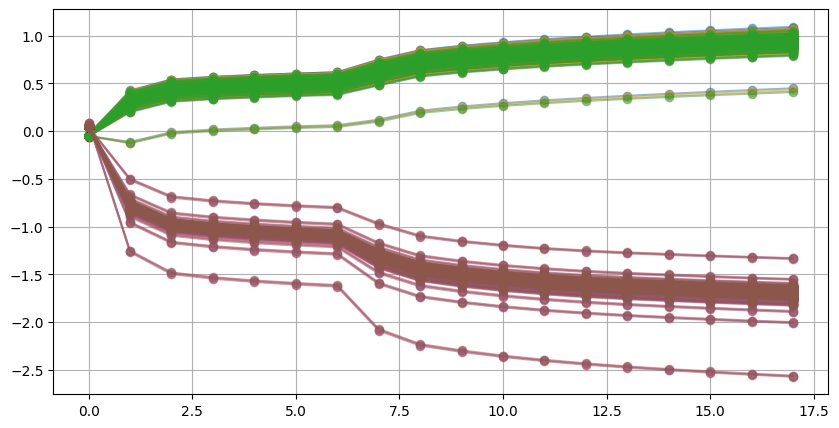

In [49]:
# PLOT THE VARIANCE IN SENSORS
colormap = sns.color_palette("tab10", n_colors=6)
plt.figure(figsize=(10,5))
for i, (key, value) in enumerate(creep_matrices.items()):    
    plt.plot(value.T, color = colormap[i], alpha = 0.5, marker='o')

plt.grid()
plt.show()

In [ ]:
for s, val in creep_matrices.items():
    print(s, np.nanargmin(val.sum(axis=0)), np.nanargmax(val.sum(axis=0)))
    

G_TILX_PE11_CB1100_0 0 0
G_TILX_PE12_CB1100_0 0 0
G_TILX_PE13_CB1100_0 0 0
G_TILX_PE21_CB0400_0 0 0
G_TILX_PE22_CB0400_0 0 0
G_TILX_PE23_CB0400_0 0 0


In [40]:
# HELPINVESTIGATE
# itr = loadcase_timesheet["LC"].tolist()
# print(len(itr))
# print(itr)
# dfs = []
# for i in itr:
#     # r = results.query("'LC ' == @i")
#     r = results[results["LC "] == i]
#     dfs.append(r)
# df = pd.concat(dfs)
# df[df["LC "] == 4045].head(150)

In [41]:
# clear folder from redundant files 
DOE = pd.read_csv(f"./QMC-Initial/{resultfolder}/doe_design.csv")
# DOE[DOE.columns[3:]] = DOE[DOE.columns[3:]].apply(lambda x: pd.to_numeric(x, errors='coerce'))
DOE.head()

,fcm_FT1,fcm_FT2,fcm_a10,fcm_a20,fcm_CIPC,fcm_CIPC_a20,kz10,kh10,kr10,kz20,kh20,kr20,kz30,kh30
0,36.64,72.59,51.94,45.80,43.01,54.48,382800.0,59030.0,789500.0,308100.0,76880.0,233100.0,10570.0,1515.0
1,34.54,71.78,59.75,49.09,44.57,53.97,357900.0,73750.0,841300.0,318700.0,52680.0,321800.0,15170.0,1649.0
2,41.84,70.56,57.10,50.66,42.12,54.15,227900.0,77590.0,766000.0,165600.0,68890.0,177400.0,18580.0,2070.0
3,40.98,61.09,55.01,57.50,45.41,54.92,322000.0,58270.0,860100.0,154500.0,60560.0,218900.0,13430.0,895.8
4,38.19,63.55,56.99,46.11,42.67,53.33,344500.0,78630.0,769100.0,95380.0,95240.0,231500.0,23600.0,2477.0


In [42]:
# collect to matricies
matricies = {} 
ival = get_results_by_id(0)
ival = get_np_data(ival)
for key, value in ival.items():
    matricies[key] = value[np.newaxis,...] 

for id in range(1,NEXP):
    crossings = get_results_by_id(id)   
    if crossings is None:
        for key, value in matricies.items():
            matricies[key] = np.concatenate([value, np.full(value.shape[-1], np.nan)[np.newaxis,...]], axis=0)   
    else:
        crossings = get_np_data(crossings)
        for key, value in matricies.items():
            matricies[key] = np.concatenate([value, crossings[key][np.newaxis,...]], axis=0)   

FILE for 247 NOT FOUND
FILE for 263 NOT FOUND
FILE for 265 NOT FOUND
FILE for 266 NOT FOUND
FILE for 267 NOT FOUND
FILE for 268 NOT FOUND
FILE for 269 NOT FOUND
FILE for 270 NOT FOUND
FILE for 271 NOT FOUND
FILE for 272 NOT FOUND
FILE for 273 NOT FOUND
FILE for 274 NOT FOUND
FILE for 275 NOT FOUND
FILE for 276 NOT FOUND
FILE for 277 NOT FOUND
FILE for 278 NOT FOUND
FILE for 279 NOT FOUND
FILE for 280 NOT FOUND
FILE for 281 NOT FOUND
FILE for 282 NOT FOUND
FILE for 283 NOT FOUND
FILE for 284 NOT FOUND
FILE for 285 NOT FOUND
FILE for 286 NOT FOUND
FILE for 287 NOT FOUND
FILE for 288 NOT FOUND
FILE for 289 NOT FOUND
FILE for 290 NOT FOUND
FILE for 291 NOT FOUND
FILE for 292 NOT FOUND
FILE for 293 NOT FOUND
FILE for 294 NOT FOUND
FILE for 295 NOT FOUND
FILE for 296 NOT FOUND
FILE for 297 NOT FOUND
FILE for 298 NOT FOUND
FILE for 299 NOT FOUND


In [43]:
# save np matricies
matricies[1140][829,:]

IndexError: index 829 is out of bounds for axis 0 with size 300

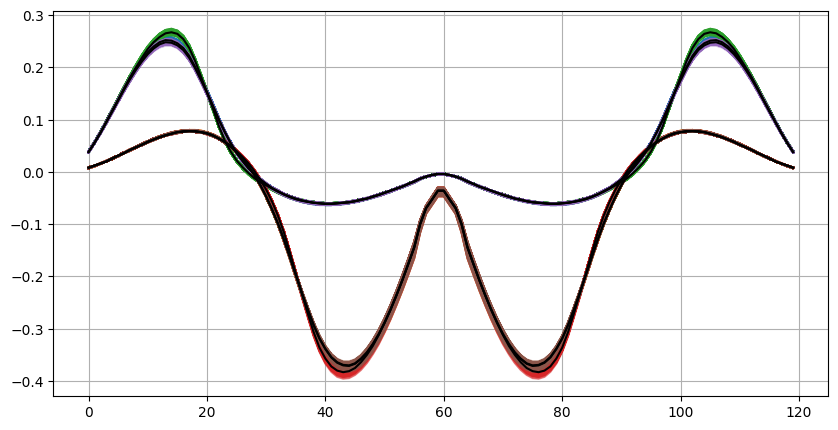

In [ ]:
# crossings[crossings["NODE "] == 1140].plot(y=crossings.columns[-2])

# get np 

colormap = sns.color_palette("tab10", n_colors=6)
plt.figure(figsize=(10,5))
for i, (key, value) in enumerate(matricies.items()):    
    plt.plot(value.T * 4.9/4.1, color = colormap[i], alpha = 0.5 )

crossings = get_results_by_id(0,".bl-transfer/cedric-model-eval/openlab-sensors-export.csv")      
crossings = get_np_data(crossings)
for i, (key, value) in enumerate(crossings.items()):    
    plt.plot(value, color = 'black', alpha = 1 )
plt.grid()
plt.show()

In [ ]:
pdl.time(hour=0, second=30) - pdl.time(hour=0, minute=1, second=30)
the_max_time = pdl.parse('2024-06-05 11:26:34.200') # which correspondes to position 103 in measurements, here 13
the_middle_time = pdl.parse('2024-06-05 11:26:58.800') # which correspondes to position 225 in measurements, here 59
interval_in_s = (the_middle_time-the_max_time).total_seconds()
increment_in_s = interval_in_s / 46
increment_in_s

0.5347826086956522

In [ ]:

resultfiles = glob.glob(f"QMC-Initial/{resultfolder}/*/*.csv")
len(resultfiles)
print(resultfiles[0:7])
print(resultfiles[-1])
 

['QMC-Initial/qmc/0/openlab-sensors-export.csv', 'QMC-Initial/qmc/1/openlab-sensors-export.csv', 'QMC-Initial/qmc/10/openlab-sensors-export.csv', 'QMC-Initial/qmc/100/openlab-sensors-export.csv', 'QMC-Initial/qmc/101/openlab-sensors-export.csv', 'QMC-Initial/qmc/102/openlab-sensors-export.csv', 'QMC-Initial/qmc/103/openlab-sensors-export.csv']
QMC-Initial/qmc/999/openlab-sensors-export.csv


In [ ]:
counter = 0
nums = []

for rf in resultfiles:
    nums.append(int(rf.split("/")[2]))
nums.sort()
# for n in nums:
#     if not n == counter:
#         print("num missing: ", n)
#     counter += 1
